In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))
import pandas as pd
pd.set_option("display.width", 200)
from src.utils.spark_session import crear_spark
from src.utils.eda import *
from src.utils.outliers import resumen_atipicos
from src.features import TARGET, leer_datos, preparar_features, preparar_target

In [2]:
spark = crear_spark("eda")
df = preparar_target(preparar_features(leer_datos(spark, "../data/web_phishing.csv"))).cache()
df.limit(5).toPandas()

,url_length,n_dots,n_hypens,n_underline,n_slash,n_questionmark,n_equal,n_at,n_and,n_exclamation,n_space,n_tilde,n_comma,n_plus,n_asterisk,n_hastag,n_dollar,n_percent,n_redirection,phishing
0,37.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
1,77.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
2,126.0,4.0,1.0,2.0,0.0,1.0,3.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1
3,18.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0
4,55.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0


In [3]:
resumen_datos(df)

Shape: (100077, 20) | Duplicados: 78186 (78.13%)


,tipo,n_nulos,pct_nulos,n_unicos,pct_ceros,min,media,max
variable,,,,,,,,
url_length,double,0,0.0,490,0.00,4.0,39.177683,4165.0
n_dots,double,0,0.0,23,0.00,1.0,2.224397,24.0
n_hypens,double,0,0.0,33,79.95,0.0,0.405188,43.0
n_underline,double,0,0.0,22,92.98,0.0,0.137724,21.0
n_slash,double,0,0.0,25,58.89,0.0,1.135386,44.0
n_questionmark,double,0,0.0,6,97.70,0.0,0.024391,9.0
n_equal,double,0,0.0,22,91.13,0.0,0.215834,23.0
n_at,double,0,0.0,15,98.05,0.0,0.022143,43.0
n_and,double,0,0.0,21,95.44,0.0,0.143330,26.0


In [4]:
distribucion_target(df, TARGET)

Ratio de desbalance (mayoritaria/minoritaria): 1.75 : 1


,n,pct
phishing,,
0,63715,63.67
1,36362,36.33


In [5]:
detectar_columnas_problema(df)

constantes: []
tipo_id: []
muchos_nulos: []


{'constantes': [], 'tipo_id': [], 'muchos_nulos': []}

In [7]:
num_cols, cat_cols = tipos_variables(df, TARGET)

Numéricas (19): ['url_length', 'n_dots', 'n_hypens', 'n_underline', 'n_slash', 'n_questionmark', 'n_equal', 'n_at', 'n_and', 'n_exclamation', 'n_space', 'n_tilde', 'n_comma', 'n_plus', 'n_asterisk', 'n_hastag', 'n_dollar', 'n_percent', 'n_redirection']
Categóricas (0): []


In [8]:
tasa_target_por_presencia(df, num_cols, TARGET)

Tasa base: 0.3633


,pct_mayor_0,tasa_si_0,tasa_si_mayor_0,lift_mayor_0
variable,,,,
n_hastag,0.01,0.363270,1.000000,2.75
n_dollar,0.06,0.362926,1.000000,2.75
n_at,1.95,0.350676,0.998977,2.75
n_asterisk,0.07,0.362914,1.000000,2.75
n_and,4.56,0.336690,0.921693,2.54
n_questionmark,2.30,0.350424,0.911458,2.51
n_equal,8.87,0.311452,0.896754,2.47
n_tilde,0.29,0.361852,0.870307,2.40
n_comma,0.15,0.362657,0.824324,2.27


In [9]:
resumen_atipicos(df, num_cols)

,variable,lim_inf,lim_sup,n_bajo,n_alto,pct_atipicos,nota
0,url_length,-21.0,83.0,0,8125,8.12,
1,n_slash,-3.0,5.0,0,3511,3.51,
2,n_redirection,-1.5,2.5,0,1392,1.39,
3,n_hypens,NaN,NaN,0,0,0.00,IQR=0: no se aplica tratamiento
4,n_dots,NaN,NaN,0,0,0.00,IQR=0: no se aplica tratamiento
5,n_questionmark,NaN,NaN,0,0,0.00,IQR=0: no se aplica tratamiento
6,n_underline,NaN,NaN,0,0,0.00,IQR=0: no se aplica tratamiento
7,n_at,NaN,NaN,0,0,0.00,IQR=0: no se aplica tratamiento
8,n_and,NaN,NaN,0,0,0.00,IQR=0: no se aplica tratamiento
9,n_exclamation,NaN,NaN,0,0,0.00,IQR=0: no se aplica tratamiento


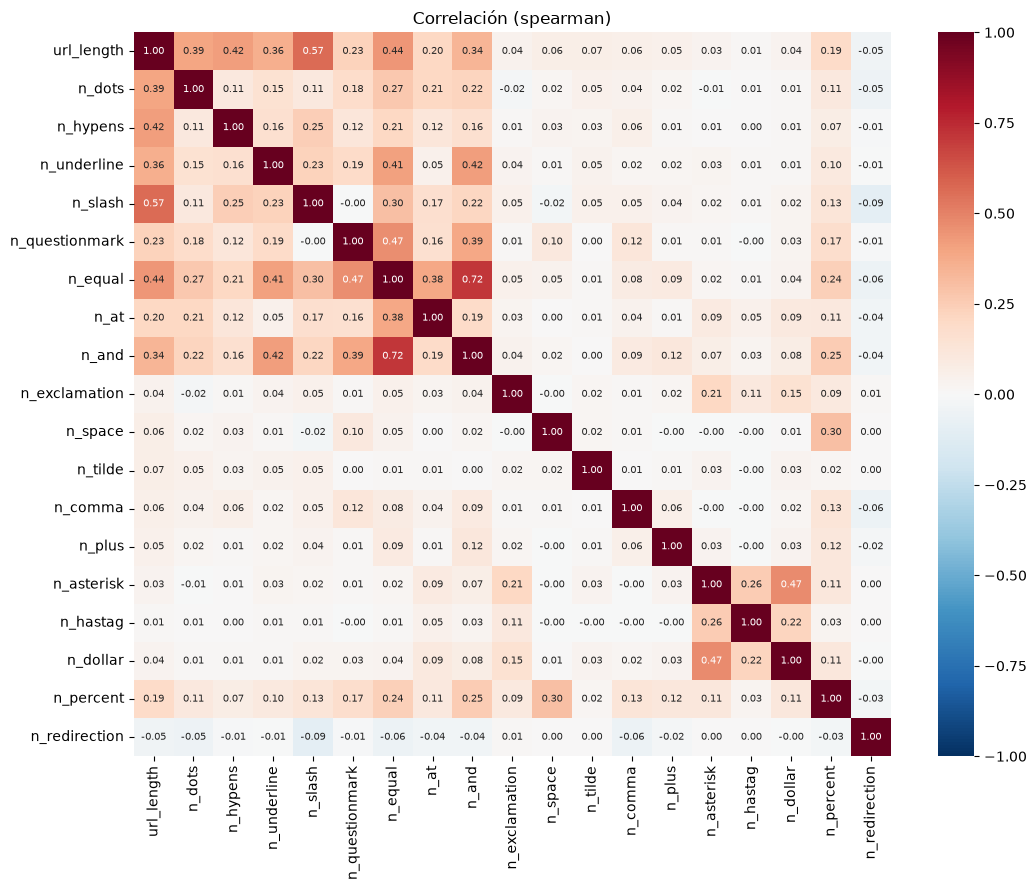

In [10]:
graficar_correlacion(df, num_cols);

In [11]:
pares_correlacionados(df, num_cols, umbral=0.5)

,var_1,var_2,corr
1,n_equal,n_and,0.715735
0,url_length,n_slash,0.567735


In [12]:
from pyspark.sql import functions as F
feats = [c for c in df.columns if c != TARGET]
grupos = df.groupBy(feats).agg(F.countDistinct(TARGET).alias("etiquetas"), F.count("*").alias("n"))
print("Combinaciones distintas de variables:", grupos.count())
print("Combinaciones con ambas etiquetas (0 y 1):", grupos.filter("etiquetas > 1").count())

Combinaciones distintas de variables: 19978
Combinaciones con ambas etiquetas (0 y 1): 1913


In [13]:
spark.stop()